Dataset loaded from: /kaggle/input/datasets/uciml/iris/Iris.csv

FIRST FIVE ROWS
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0            5.1           3.5            1.4           0.2  Iris-setosa
1            4.9           3.0            1.4           0.2  Iris-setosa
2            4.7           3.2            1.3           0.2  Iris-setosa
3            4.6           3.1            1.5           0.2  Iris-setosa
4            5.0           3.6            1.4           0.2  Iris-setosa

DATASET SHAPE
Rows: 150
Features: 4

CLASS DISTRIBUTION
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

MISSING VALUES IN FEATURES
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
dtype: int64


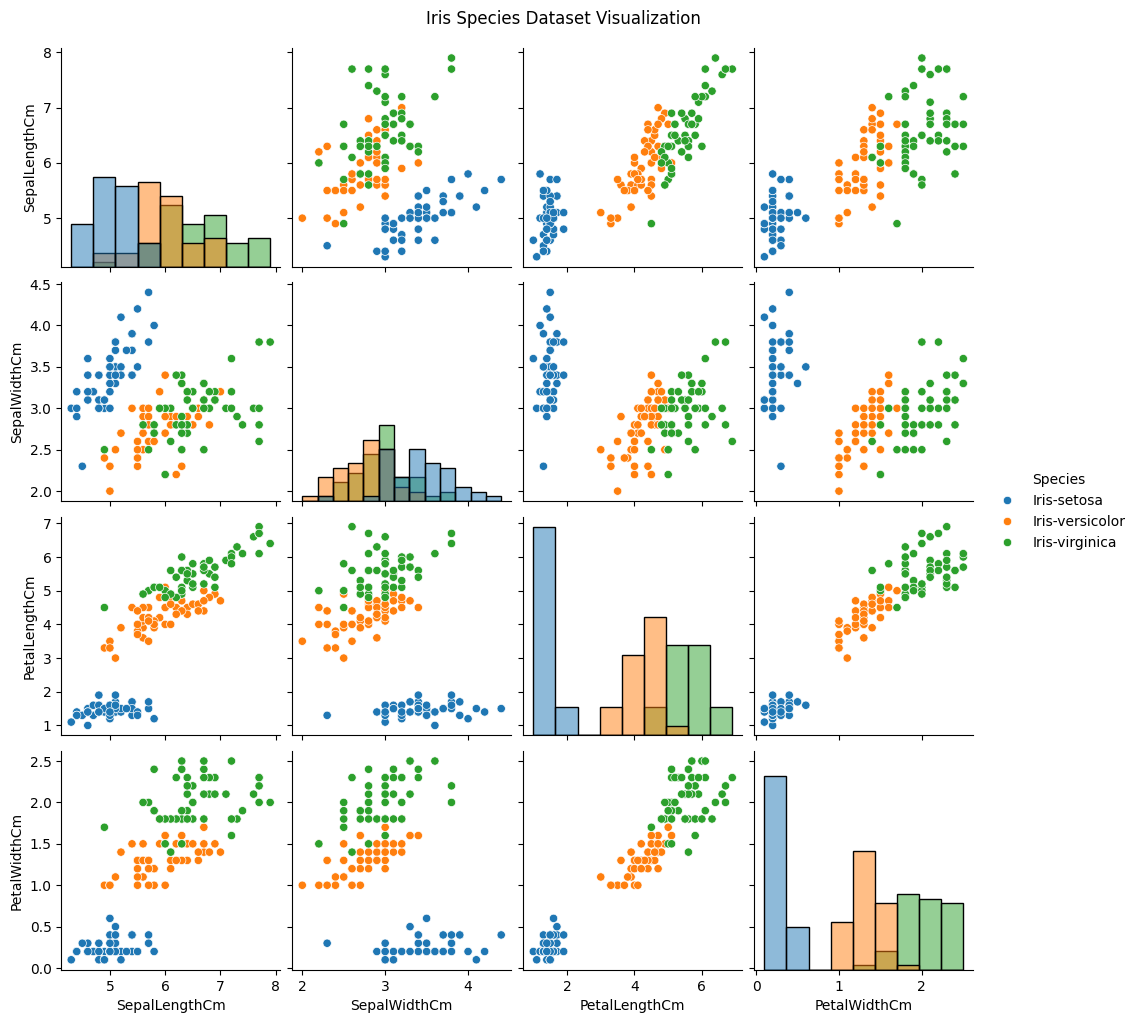


TRAINING SAMPLES: 120
TESTING SAMPLES: 30

Gradient Boosting model trained successfully!

ACTUAL CLASSES
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]

PREDICTED CLASSES
[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 2 1 0 2 0]

MODEL ACCURACY
Accuracy: 0.9667
Accuracy Percentage: 96.67 %

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

CONFUSION MATRIX
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]


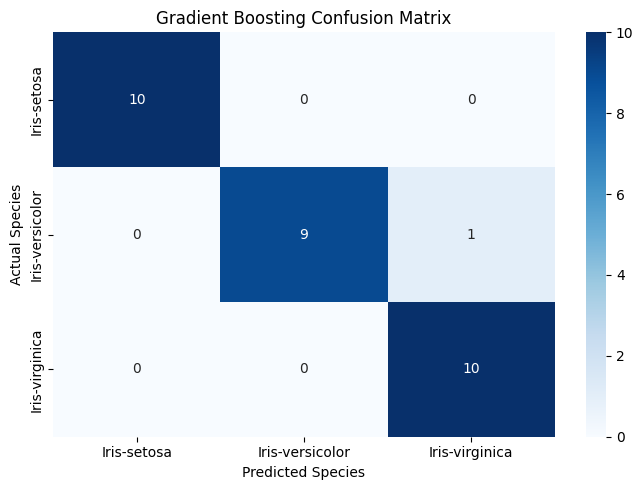


FEATURE IMPORTANCE
      Feature  Importance
 PetalWidthCm    0.635637
PetalLengthCm    0.345655
 SepalWidthCm    0.015130
SepalLengthCm    0.003578


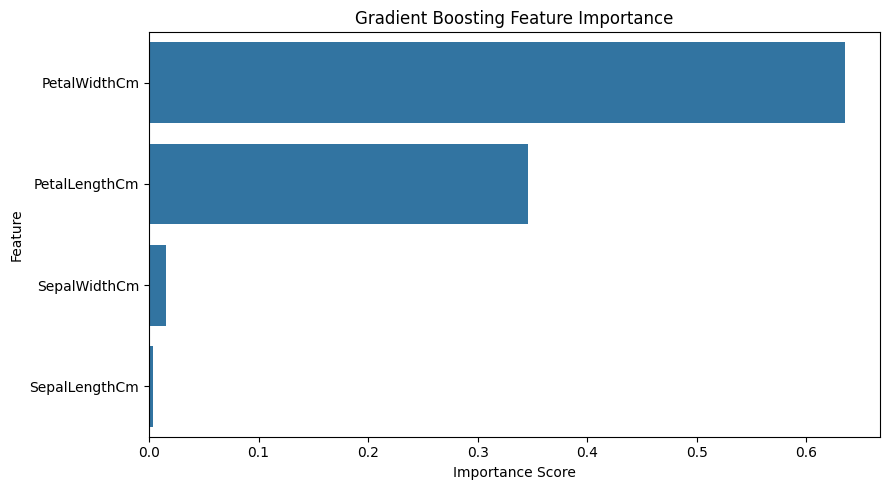

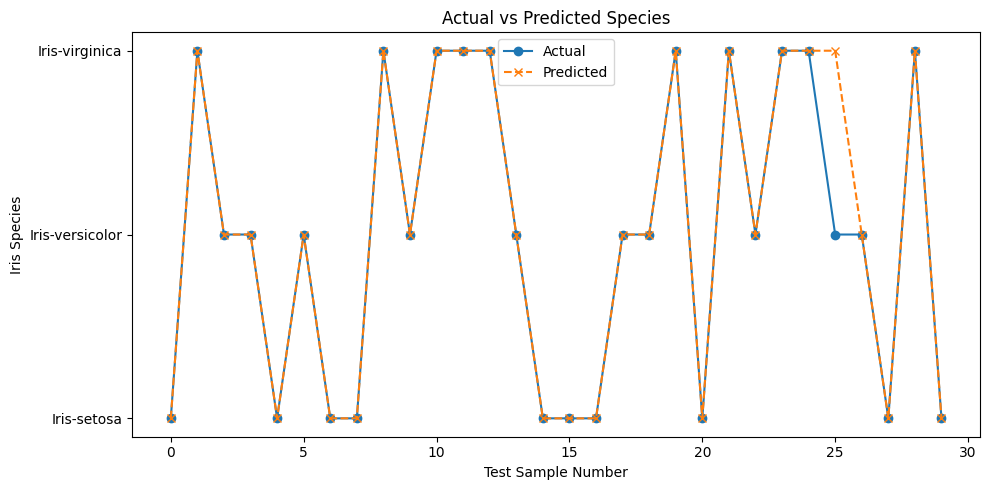


NEW FLOWER PREDICTION
Measurements: {'SepalLengthCm': 5.1, 'SepalWidthCm': 3.5, 'PetalLengthCm': 1.4, 'PetalWidthCm': 0.2}
Predicted Species: Iris-setosa

PREDICTION PROBABILITIES
Iris-setosa: 100.00%
Iris-versicolor: 0.00%
Iris-virginica: 0.00%

PROGRAM COMPLETED SUCCESSFULLY


In [1]:
# GRADIENT BOOSTING CLASSIFICATION USING IRIS SPECIES DATASET

# STEP 1: Import Libraries
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# STEP 2: Load the Kaggle Iris Species CSV if available
# Otherwise, use the built-in Iris dataset.

csv_files = glob.glob("/kaggle/input/datasets/uciml/iris/Iris.csv", recursive=True)
df = None
target_col = None

possible_targets = [
    "species", "class", "variety", "iris",
    "target", "plant species"
]

for file in csv_files:
    temp = pd.read_csv(file)
    column_lookup = {
        str(col).strip().lower(): col for col in temp.columns
    }

    found_target = next(
        (column_lookup[name] for name in possible_targets
         if name in column_lookup),
        None
    )

    if found_target is not None:
        df = temp.copy()
        target_col = found_target
        print("Dataset loaded from:", file)
        break

if df is not None:
    # Remove common unnecessary index columns
    df = df.drop(
        columns=[
            col for col in df.columns
            if str(col).strip().lower() in ["id", "unnamed: 0"]
        ],
        errors="ignore"
    )

    # Keep rows with a known target
    df = df.dropna(subset=[target_col]).copy()

    # Convert target labels to numeric class codes
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(df[target_col].astype(str))

    # Use numeric feature columns only
    X = df.drop(columns=[target_col])
    X = X.select_dtypes(include=np.number)

    # Remove rows with missing feature values
    valid_rows = X.notna().all(axis=1)
    X = X.loc[valid_rows]
    y = y[valid_rows.to_numpy()]

    class_names = label_encoder.classes_
    feature_names = X.columns.tolist()

else:
    iris = load_iris(as_frame=True)
    X = iris.data.copy()
    y = iris.target.to_numpy()
    class_names = iris.target_names
    feature_names = X.columns.tolist()

    df = X.copy()
    df["species"] = [class_names[i] for i in y]

    print("Kaggle CSV not found. Using built-in Iris dataset.")

# STEP 3: Display Dataset

print("\nFIRST FIVE ROWS")
print(df.head())

print("\nDATASET SHAPE")
print("Rows:", len(X))
print("Features:", X.shape[1])

print("\nCLASS DISTRIBUTION")
print(pd.Series(y).map(
    dict(enumerate(class_names))
).value_counts())

print("\nMISSING VALUES IN FEATURES")
print(X.isnull().sum())

# STEP 4: Visualize the Dataset

plot_df = X.copy()
plot_df["Species"] = [
    class_names[i] for i in y
]

sns.pairplot(
    plot_df,
    hue="Species",
    diag_kind="hist"
)
plt.suptitle("Iris Species Dataset Visualization", y=1.02)
plt.show()

# STEP 5: Split Data into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTRAINING SAMPLES:", len(X_train))
print("TESTING SAMPLES:", len(X_test))

# STEP 6: Create Gradient Boosting Model

model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# STEP 7: Train the Model

model.fit(X_train, y_train)

print("\nGradient Boosting model trained successfully!")

# STEP 8: Predict Test Data

y_pred = model.predict(X_test)

print("\nACTUAL CLASSES")
print(y_test)

print("\nPREDICTED CLASSES")
print(y_pred)

# STEP 9: Calculate Accuracy

accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 50)
print("MODEL ACCURACY")
print("=" * 50)
print("Accuracy:", round(accuracy, 4))
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

# STEP 10: Classification Report

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# STEP 11: Confusion Matrix Graph

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

print("CONFUSION MATRIX")
print(cm)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Gradient Boosting Confusion Matrix")
plt.tight_layout()
plt.show()

# STEP 12: Feature Importance Graph

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\nFEATURE IMPORTANCE")
print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)
plt.title("Gradient Boosting Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# STEP 13: Actual vs Predicted Graph

plt.figure(figsize=(10, 5))
sample_numbers = np.arange(len(y_test))

plt.plot(
    sample_numbers,
    y_test,
    marker="o",
    linestyle="-",
    label="Actual"
)

plt.plot(
    sample_numbers,
    y_pred,
    marker="x",
    linestyle="--",
    label="Predicted"
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)
plt.xlabel("Test Sample Number")
plt.ylabel("Iris Species")
plt.title("Actual vs Predicted Species")
plt.legend()
plt.tight_layout()
plt.show()

# STEP 14: Predict a New Flower
# Values must follow the feature column order printed above.
# These measurements correspond to the standard Iris features.

if (
    len(feature_names) == 4
    and all(
        "sepal" in str(f).lower()
        or "petal" in str(f).lower()
        for f in feature_names
    )
):
    new_flower = pd.DataFrame(
        [[5.1, 3.5, 1.4, 0.2]],
        columns=feature_names
    )

    prediction = model.predict(new_flower)[0]
    probabilities = model.predict_proba(new_flower)[0]

    print("\nNEW FLOWER PREDICTION")
    print("Measurements:", new_flower.iloc[0].to_dict())
    print("Predicted Species:", class_names[prediction])

    print("\nPREDICTION PROBABILITIES")
    for name, prob in zip(model.classes_, probabilities):
        print(
            f"{class_names[name]}: {prob * 100:.2f}%"
        )
else:
    print(
        "\nNew flower prediction skipped because the CSV "
        "feature columns are not the standard four Iris features."
    )

print("\nPROGRAM COMPLETED SUCCESSFULLY")